# Yamaguchi decomposition of a Biomass L1c stack

1. **Query and download**: finds the L1c stack (coregistered acquisitions, common slant range grid) with the most
   acquisitions over a point in the MAAP catalogue and downloads abs/phase tiffs and lut.nc of each acquisition.
2. **Install**: installs PyPolSARpro from conda-forge into the running kernel if it is missing.
3. **Decomposition**: multilook to square ground pixels and Yamaguchi 4-component decomposition of the complete scene
   (optional: only an azimuth strip around the point).
4. **Analysis**: Yamaguchi RGB per date, components, scattering fractions over time.

The components are given in dB by default (`UNIT = "dB"`) for the downstream analysis; `UNIT = "power"` gives
linear power, e.g. for display on the 0-1 scale of the PyPolSARpro tutorial.

Functions are defined in the notebook (section 0). Needs `token.txt` (MAAP offline token, gitignored) next to this notebook and the
MAAP client secret in env var `MAAP_CLIENT_SECRET` (e.g. run `%env MAAP_CLIENT_SECRET=...` once, do not commit it).

In [1]:
import os
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pystac
import rasterio
import requests
import xarray as xr
from pystac_client import Client

LAT, LON = 14.80, 79.57  # point of interest [deg]
START, END = "2026-08-01", "2026-08-31"  # search period
DATA_DIR = Path("data")  # one folder per product, gitignored
# None = complete scene (~20 700 azimuth lines, ~140 km). A number crops to that many azimuth lines on each side of the
# point (e.g. 1750 -> ~24 km strip), which is faster and needs less memory. Range is always read completely.
HALF_ROWS = None
UNIT = "dB"  # unit of the components: "dB" (default, downstream analysis) or "power" (linear, for display)

## 0. Functions
Search, download, loading and Yamaguchi decomposition of Biomass L1c (STA) stacks. PyPolSARpro is imported only
inside `decompose`, so search and download work without it.

In [2]:
CATALOG_URL = "https://catalog.maap.eo.esa.int/catalogue/"
TOKEN_URL = "https://iam.maap.eo.esa.int/realms/esa-maap/protocol/openid-connect/token"
ASSETS = ["enclosure_i_abs_tiff", "enclosure_i_phase_tiff", "enclosure_nc"]  # abs, phase, lut.nc
EARTH_RADIUS = 6371e3  # [m]


def get_token() -> str:
    """Return a short-lived MAAP access token from the offline token in token.txt."""
    data = {
        "client_id": "offline-token",
        "client_secret": os.environ["MAAP_CLIENT_SECRET"],
        "grant_type": "refresh_token",
        "refresh_token": Path("token.txt").read_text().strip(),
        "scope": "offline_access openid",
    }
    response = requests.post(TOKEN_URL, data=data, timeout=60)
    response.raise_for_status()
    return response.json()["access_token"]


def find_stack(lat: float, lon: float, start: str, end: str) -> list[pystac.Item]:
    """Return the L1c stack with the most acquisitions over a point, sorted by date.

    Parameters
    ----------
    lat, lon : float
        Point of interest [deg].
    start, end : str
        Search period, ISO dates (e.g. "2026-08-01").

    Returns
    -------
    list of pystac.Item
        Products of one stack (same eofeos:stack_id), oldest first.
    """
    search = Client.open(CATALOG_URL).search(
        collections=["BiomassLevel1c"],
        intersects={"type": "Point", "coordinates": [lon, lat]},
        datetime=f"{start}/{end}",
        method="GET",
    )
    stacks = defaultdict(list)
    for item in search.items():
        stacks[item.properties["eofeos:stack_id"]].append(item)
    for stack_id, items in stacks.items():
        print(stack_id, len(items), "acquisitions")
    return sorted(max(stacks.values(), key=len), key=lambda item: item.datetime)


def download(item: pystac.Item, token: str, data_dir: Path) -> Path:
    """Download abs, phase tiff and lut.nc of one product into data_dir/<product id>/, skipping existing files."""
    product_dir = data_dir / item.id
    product_dir.mkdir(parents=True, exist_ok=True)
    for key in ASSETS:
        href = item.assets[key].href
        path = product_dir / href.split("/")[-1]
        if path.exists():
            continue
        part = path.with_suffix(".part")
        with requests.get(href, headers={"Authorization": f"Bearer {token}"}, stream=True, timeout=300) as response:
            response.raise_for_status()
            with open(part, "wb") as f:
                f.writelines(response.iter_content(2**24))
        part.rename(path)
        print("downloaded", path.name, f"{path.stat().st_size / 1e6:.0f} MB")
    return product_dir


def pixel_of(lut_path: str | Path, shape: tuple[int, int], lat: float, lon: float) -> tuple[int, int]:
    """Image pixel (azimuth line, range sample) closest to a point, from the lat/lon grid of the product LUT."""
    geo = xr.open_dataset(lut_path, group="geometry")
    dist = (geo.latitude.values - lat) ** 2 + ((geo.longitude.values - lon) * np.cos(np.radians(lat))) ** 2
    i, j = np.unravel_index(np.nanargmin(dist), dist.shape)
    return int(i * shape[0] / dist.shape[0]), int(j * shape[1] / dist.shape[1])


def load_s(abs_path: str | Path, phase_path: str | Path, rows: tuple[int, int]) -> xr.Dataset:
    """Load a crop of the scattering matrix S of one L1c product.

    Parameters
    ----------
    abs_path, phase_path : str or Path
        Local path or URL of the i_abs and i_phase tiffs (URLs need a rasterio.Env with the bearer token).
    rows : tuple of int
        First and last azimuth line of the crop [pixel].

    Returns
    -------
    xr.Dataset
        Complex hh, hv, vh, vv (beta-nought amplitude [-], slant range geometry), dims (y, x). No-data (swath edges)
        is NaN.
    """
    window = (rows, (0, None))
    with rasterio.open(abs_path) as src:
        amp = src.read(window=window, masked=True).filled(np.nan)
    with rasterio.open(phase_path) as src:
        phase = src.read(window=window, masked=True).filled(np.nan)
    slc = amp * np.exp(1j * phase)  # band order HH, HV, VH, VV (tiff tag PolarisationsSequence)
    dims = ("y", "x")
    return xr.Dataset(
        {pol: (dims, slc[i]) for i, pol in enumerate(["hh", "hv", "vh", "vv"])},
        coords={"y": np.arange(rows[0], rows[0] + slc.shape[1]), "x": np.arange(slc.shape[2])},
        attrs={"poltype": "S", "description": "Scattering matrix"},
    ).chunk("auto")


def multilook_factor(lut_path: str | Path, shape: tuple[int, int]) -> int:
    """Azimuth looks that give square ground pixels, from the lat/lon grid of the product LUT.

    Parameters
    ----------
    lut_path : str or Path
        Product lut.nc.
    shape : tuple of int
        Full image size (azimuth lines, range samples) [pixel].

    Returns
    -------
    int
        Number of azimuth looks (range looks = 1).
    """
    geo = xr.open_dataset(lut_path, group="geometry")
    lat, lon = np.radians(geo.latitude.values), np.radians(geo.longitude.values)
    mid_az, mid_rg = lat.shape[0] // 2, lat.shape[1] // 2

    def ground_length(la: np.ndarray, lo: np.ndarray) -> float:
        dy, dx = np.diff(la), np.diff(lo) * np.cos(la[:-1])
        return EARTH_RADIUS * np.nansum(np.hypot(dy, dx))

    az_spacing = ground_length(lat[:, mid_rg], lon[:, mid_rg]) / shape[0]
    rg_spacing = ground_length(lat[mid_az], lon[mid_az]) / shape[1]
    print(f"ground pixel: azimuth {az_spacing:.1f} m, range {rg_spacing:.1f} m")
    return max(1, round(rg_spacing / az_spacing))


def decompose(s: xr.Dataset, ml_az: int, boxcar: tuple[int, int] = (3, 3), mode: str = "y4r") -> xr.Dataset:
    """Multilook S to square pixels and apply the Yamaguchi decomposition.

    Parameters
    ----------
    s : xr.Dataset
        Scattering matrix from `load_s`.
    ml_az : int
        Azimuth looks, from `multilook_factor`.
    boxcar : tuple of int
        Boxcar window (azimuth, range) applied on the multilooked image [pixel].
    mode : str
        Yamaguchi variant: "y4o" (original), "y4r" (with rotation) or "s4r".

    Returns
    -------
    xr.Dataset
        Powers odd (surface), double, volume, helix [-].
    """
    from polsarpro.decompositions import yamaguchi4
    from polsarpro.util import S_to_C3, multilook

    c3 = multilook(S_to_C3(s), dim_az=ml_az, dim_rg=1)
    return yamaguchi4(c3, boxcar_size=list(boxcar), mode=mode).compute()


def to_db(power: xr.Dataset) -> xr.Dataset:
    """Convert linear power [-] to dB; zero or negative power becomes NaN."""
    return 10 * np.log10(power.where(power > 0))


def yamaguchi_rgb(out: xr.Dataset) -> np.ndarray:
    """RGB composite of amplitudes: red = double bounce, green = volume, blue = odd (surface), each to its 98th pct."""
    rgb = np.sqrt(np.stack([out[name].values for name in ["double", "volume", "odd"]], axis=-1))
    return np.nan_to_num(np.clip(rgb / np.nanpercentile(rgb, 98, axis=(0, 1)), 0, 1))


def plot_components(out: xr.Dataset, title: str, unit: str = "dB") -> plt.Figure:
    """Plot the four Yamaguchi components on one shared scale: -30 to 0 dB, or 0-1 for power (PyPolSARpro tutorial).

    Tall images (full scene) are plotted side by side, wide images (crop) below each other.
    """
    tall = out.sizes["y"] > out.sizes["x"]
    fig, axes = plt.subplots(1, 4, figsize=(16, 12)) if tall else plt.subplots(4, 1, figsize=(12, 16))
    for ax, name in zip(axes, ["odd", "double", "volume", "helix"]):
        vmin, vmax = (-30, 0) if unit == "dB" else (0, 1)
        im = out[name].plot.imshow(ax=ax, vmin=vmin, vmax=vmax, yincrease=False, add_colorbar=False)
        ax.set_title(name)
    fig.colorbar(im, ax=axes, extend="both" if unit == "dB" else "max", label="dB" if unit == "dB" else "power [-]")
    fig.suptitle(title, fontsize=8)
    return fig

## 1. Catalogue query and download

In [3]:
# all L1c products over the point in the period, grouped by stack; the stack with most acquisitions is kept
items = find_stack(LAT, LON, START, END)

# download abs, phase and lut.nc of each acquisition (existing files are skipped)
token = get_token()
product_dirs = [download(item, token, DATA_DIR) for item in items]

dates = [item.datetime.strftime("%Y-%m-%d") for item in items]
print(len(items), "acquisitions:", dates)

BIO_S3_STA__ID_20260816T130437_20260828T130506_T_G01_M04_N0148_E0796_D_02_DXFVIW 5 acquisitions


5 acquisitions: ['2026-08-16', '2026-08-19', '2026-08-22', '2026-08-25', '2026-08-28']


## 2. Install PyPolSARpro if missing
Installs into the running kernel environment. The alternative with a separate `polsarpro` conda environment and kernel
is described in https://gist.github.com/odhondt/f9ce88acca5f91e8f3563b32a342addc

In [4]:
import importlib.util

if importlib.util.find_spec("polsarpro") is None:
    %conda install -y conda-forge::polsarpro
else:
    print("polsarpro already installed")

polsarpro already installed


## 3. Decomposition

In [5]:
# file paths of each acquisition; rglob also finds them in the measurement/ and annotation_coregistered/
# subfolders of a complete product
abs_paths = [next(d.rglob("*i_abs.tiff")) for d in product_dirs]
phase_paths = [next(d.rglob("*i_phase.tiff")) for d in product_dirs]
luts = [next(d.rglob("*lut.nc")) for d in product_dirs]

# a stack shares one grid: all images must have the same size
shapes = set()
for path in abs_paths:
    with rasterio.open(path) as src:
        shapes.add((src.height, src.width))
assert len(shapes) == 1, f"products are not on a common grid: {shapes}"
shape = shapes.pop()

# azimuth looks for square ground pixels and image pixel of the point
ml_az = multilook_factor(luts[0], shape)
row, col = pixel_of(luts[0], shape, LAT, LON)

# azimuth lines to process: complete scene or strip around the point
if HALF_ROWS is None:
    rows = (0, shape[0])
else:
    rows = (max(row - HALF_ROWS, 0), min(row + HALF_ROWS, shape[0]))
print("image", shape, "| point at pixel", (row, col), "| rows", rows, "| azimuth looks", ml_az)

ground pixel: azimuth 6.8 m, range 36.5 m


image (20758, 1517) | point at pixel (10331, 751) | rows (0, 20758) | azimuth looks 5


In [6]:
# decompose every acquisition and stack the results (linear power) along a date dimension
outs = [decompose(load_s(a, p, rows), ml_az) for a, p in zip(abs_paths, phase_paths)]
power = xr.concat(outs, dim=xr.DataArray(dates, dims="date", name="date"))

# output in the chosen unit; `power` stays available for the RGB and the fractions
stack = to_db(power) if UNIT == "dB" else power
stack

<xarray.Dataset> Size: 504MB
Dimensions:  (y: 4151, x: 1517, date: 5)
Coordinates:
  * y        (y) float64 33kB 2.0 7.0 12.0 ... 2.074e+04 2.075e+04 2.075e+04
  * x        (x) float64 12kB 0.0 1.0 2.0 3.0 ... 1.514e+03 1.515e+03 1.516e+03
  * date     (date) <U10 200B '2026-08-16' '2026-08-19' ... '2026-08-28'
Data variables:
    odd      (date, y, x) float32 126MB nan nan nan nan nan ... nan nan nan nan
    double   (date, y, x) float32 126MB nan nan nan nan nan ... nan nan nan nan
    volume   (date, y, x) float32 126MB nan nan nan nan nan ... nan nan nan nan
    helix    (date, y, x) float32 126MB nan nan nan nan nan ... nan nan nan nan
Attributes:
    poltype:      yamaguchi4_y4r
    description:  Results of the Yamaguchi 4 component decomposition (mode=y4r).

## 4. Analysis
RGB: red = double bounce, green = volume, blue = odd (surface). The red cross marks the point.

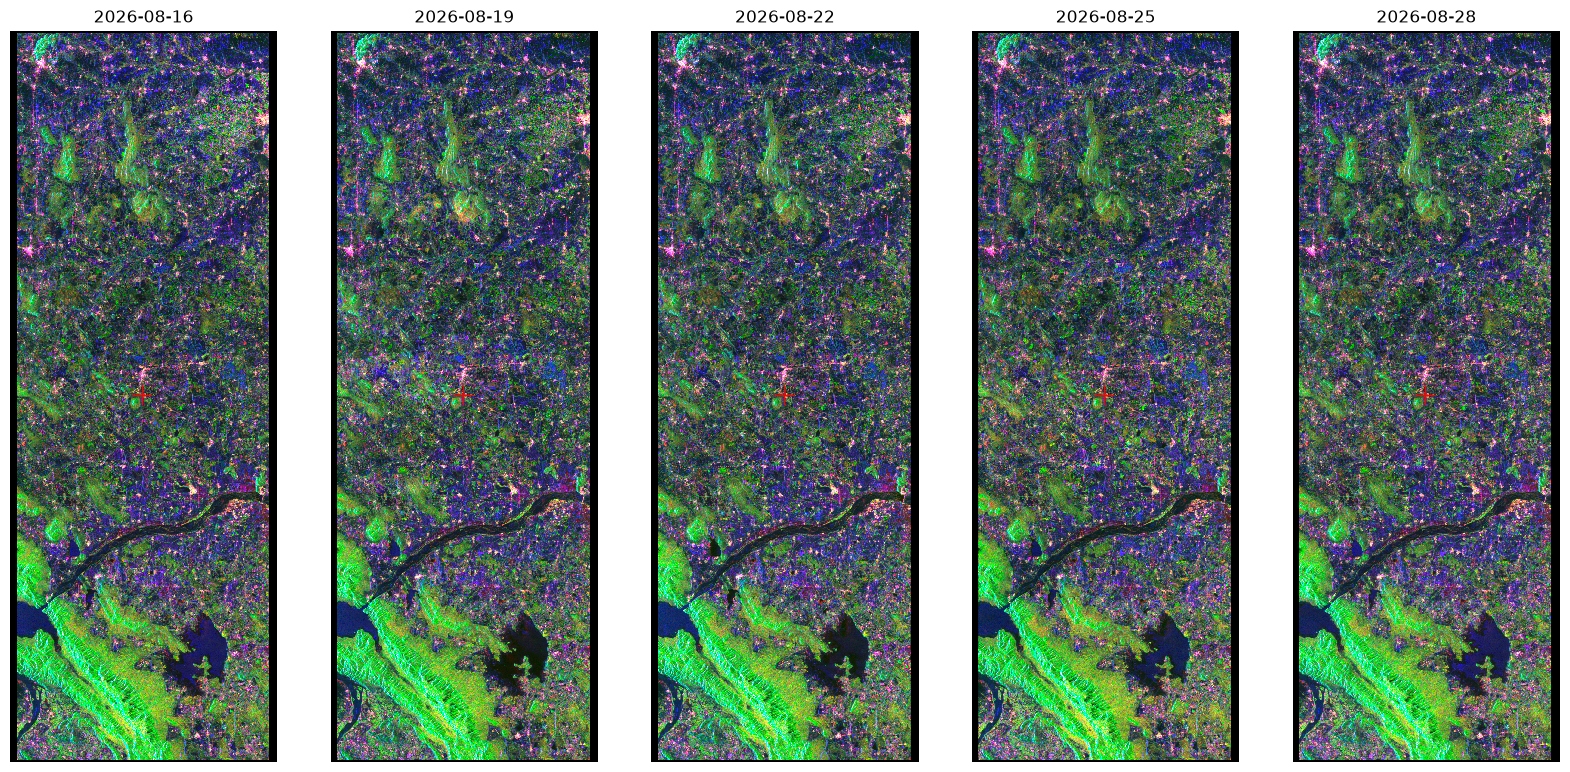

In [7]:
# tall images (complete scene) side by side, wide images (crop) below each other
tall = power.sizes["y"] > power.sizes["x"]
n = len(dates)
fig, axes = plt.subplots(1, n, figsize=(4 * n, 12)) if tall else plt.subplots(n, 1, figsize=(12, 5 * n))

for ax, date in zip(axes, dates):
    out = power.sel(date=date)  # RGB is built from linear power
    ax.imshow(yamaguchi_rgb(out), interpolation="none")
    # point: range sample is unchanged, azimuth line is counted on the multilooked grid
    ax.plot(col, int((out.y < row).sum()), "r+", markersize=15)
    ax.set_title(date)
    ax.axis("off")
plt.show()

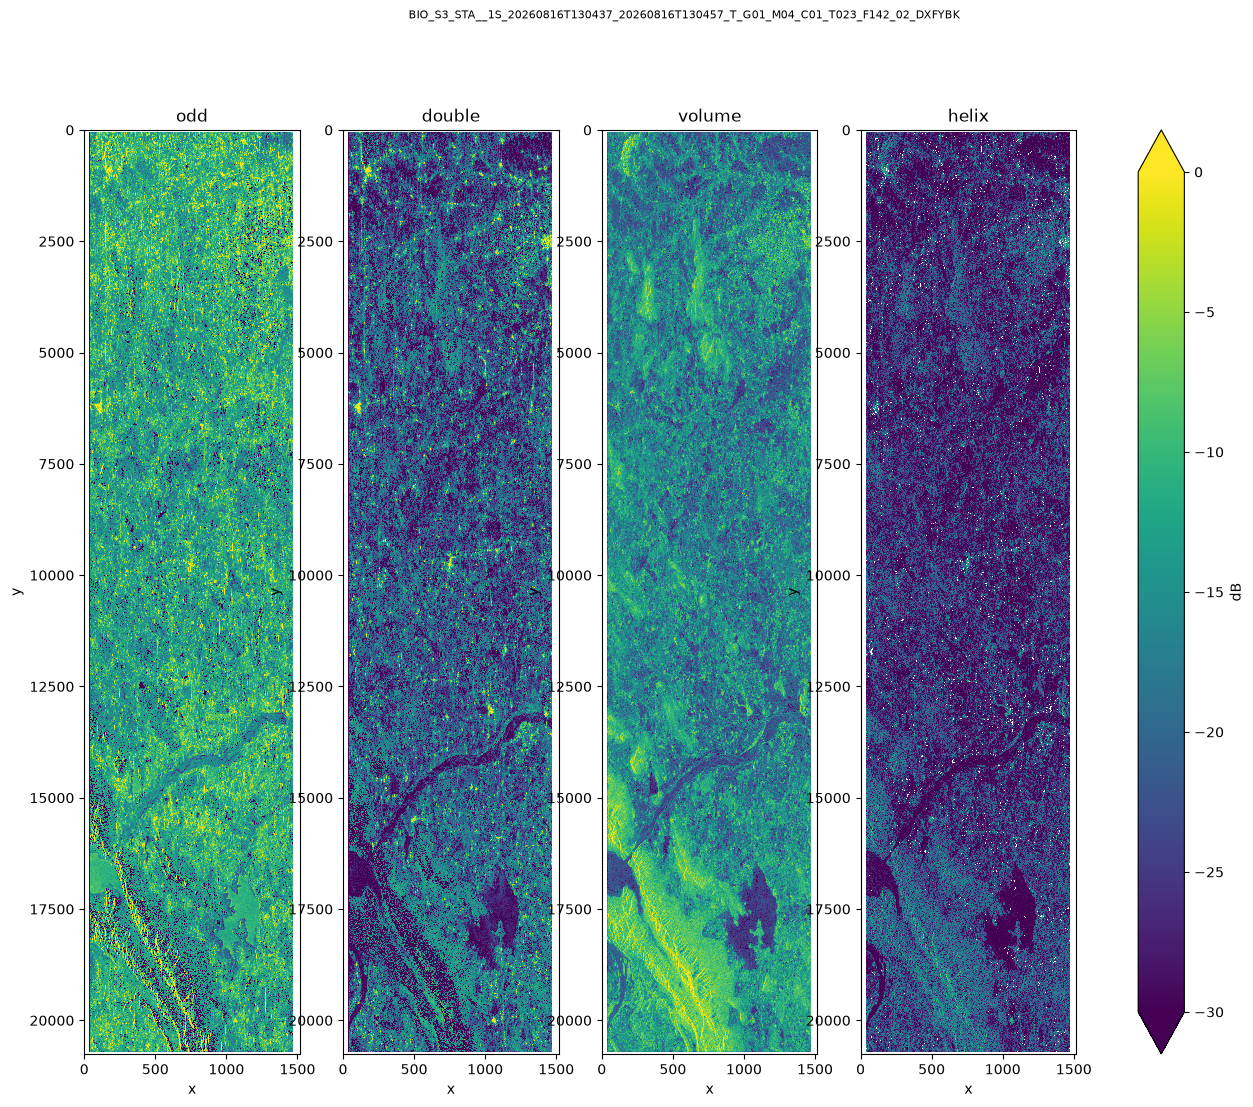

In [8]:
plot_components(stack.isel(date=0), f"{items[0].id}", UNIT)
plt.show()

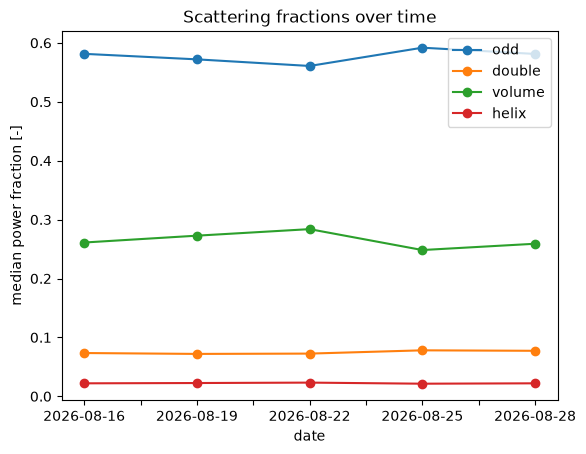

In [9]:
# share of each component in the total power per pixel (always from linear power), median over the image, per date
names = ["odd", "double", "volume", "helix"]
fractions = (power[names] / power[names].to_array().sum("variable")).median(["y", "x"])
fractions.to_dataframe()[names].plot(
    marker="o", ylabel="median power fraction [-]", title="Scattering fractions over time"
)
plt.show()